## Student Performance Indicator


dataset = https://www.kaggle.com/datasets/jagdishchavan/student-performance

### Import Data and Required Packages

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')


### Import the dataset

In [2]:
df = pd.read_csv("data/stud.csv")

In [3]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.shape

(1000, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [6]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [7]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

There are no NULL values in any columns

In [8]:
df.duplicated().sum()

np.int64(0)

There are no any duplicate values.

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [10]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

In [11]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### Insight

1. mean range close between 66 to 69.  
2. standard deviations are also close between 14 to 16.  
3. min score for maths is 0, for writing min score is 10, and last for reading score is 17.  

### Exploring data

In [12]:
df['gender'].unique()

<StringArray>
['female', 'male']
Length: 2, dtype: str

In [13]:
df['race_ethnicity'].unique()

<StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str

In [14]:
df['parental_level_of_education'].unique()

<StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str

In [15]:
df['lunch'].unique()

<StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str

In [16]:
df['test_preparation_course'].unique()

<StringArray>
['none', 'completed']
Length: 2, dtype: str

In [17]:
# define numerical and categorical columns
numerical_features = [feature for feature in df.columns if df[feature].dtypes != 'str']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'str']

# print columns
print('We have {} numerical features : {}'.format(len(numerical_features), numerical_features))
print('We have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 3 numerical features : ['math_score', 'reading_score', 'writing_score']
We have 5 categorical features : ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


## Adding columns for "Total Score" and "Average"

In [18]:
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average_score'] = df['total_score']/3
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [19]:
reading_full = df[df['reading_score'] == 100]['average_score'].count()
writing_full = df[df['writing_score'] == 100]['average_score'].count()
math_full = df[df['math_score'] == 100]['average_score'].count()   

print(f"Number of students with full marks in reading: {reading_full}")
print(f"Number of students with full marks in writing: {writing_full}")
print(f"Number of students with full marks in math: {math_full}")

Number of students with full marks in reading: 17
Number of students with full marks in writing: 14
Number of students with full marks in math: 7


In [20]:
reading_less_20 = df[df['reading_score'] <= 20]['average_score'].count()
writing_less_20 = df[df['writing_score'] <= 20]['average_score'].count()
math_less_20 = df[df['math_score'] <= 20]['average_score'].count()

print(f"Number of students with less than 20 marks in reading: {reading_less_20}")
print(f"Number of students with less than 20 marks in writing: {writing_less_20}")
print(f"Number of students with less than 20 marks in math: {math_less_20}")

Number of students with less than 20 marks in reading: 1
Number of students with less than 20 marks in writing: 3
Number of students with less than 20 marks in math: 4


## Insights
1. From above values we get Number of student with worst marks.
2. We get no. of student with best marks in each subject. 

### Histogram & KDE

<Axes: xlabel='average_score', ylabel='Count'>

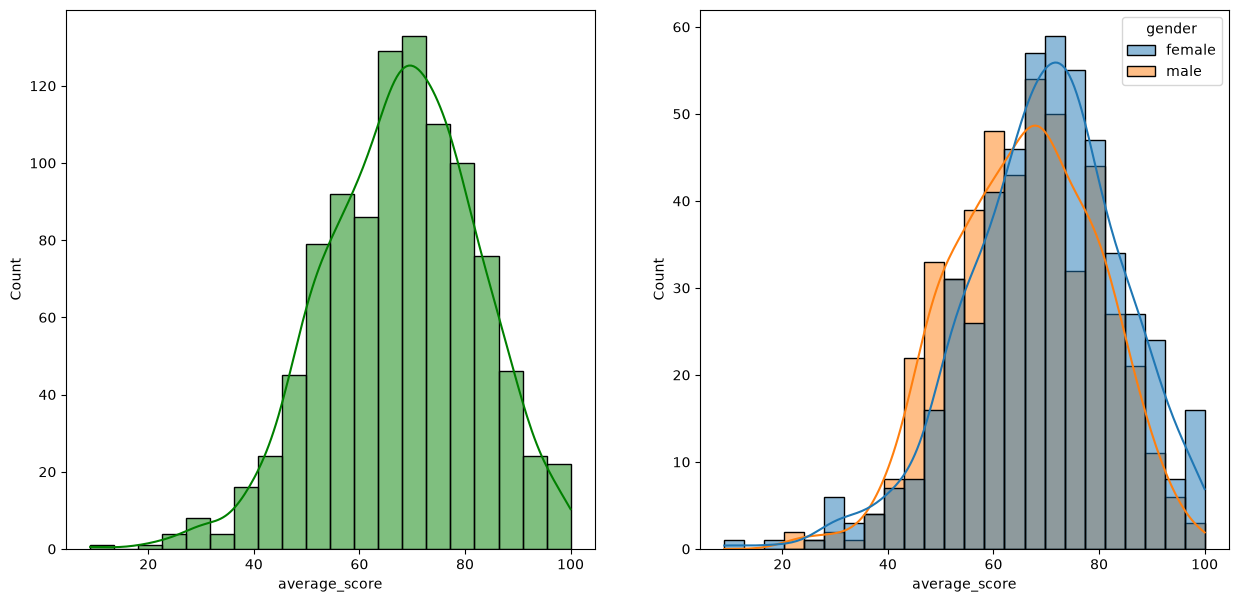

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data = df, x = 'average_score',bins = 20, kde = True, color='green')
plt.subplot(122)
sns.histplot(data = df, x = 'average_score', hue = 'gender', kde = True)

<Axes: xlabel='total_score', ylabel='Count'>

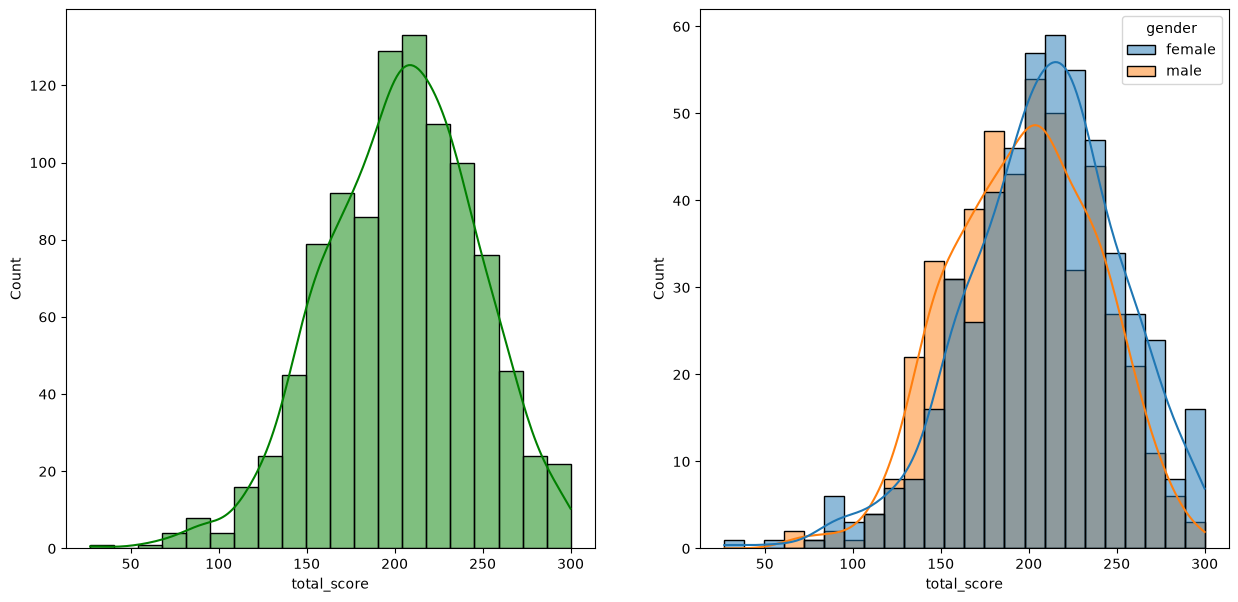

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data = df, x = 'total_score',bins = 20, kde = True, color='green')
plt.subplot(122)
sns.histplot(data = df, x = 'total_score', hue = 'gender', kde = True)

### Insights

* Female students tends to perform well then male students

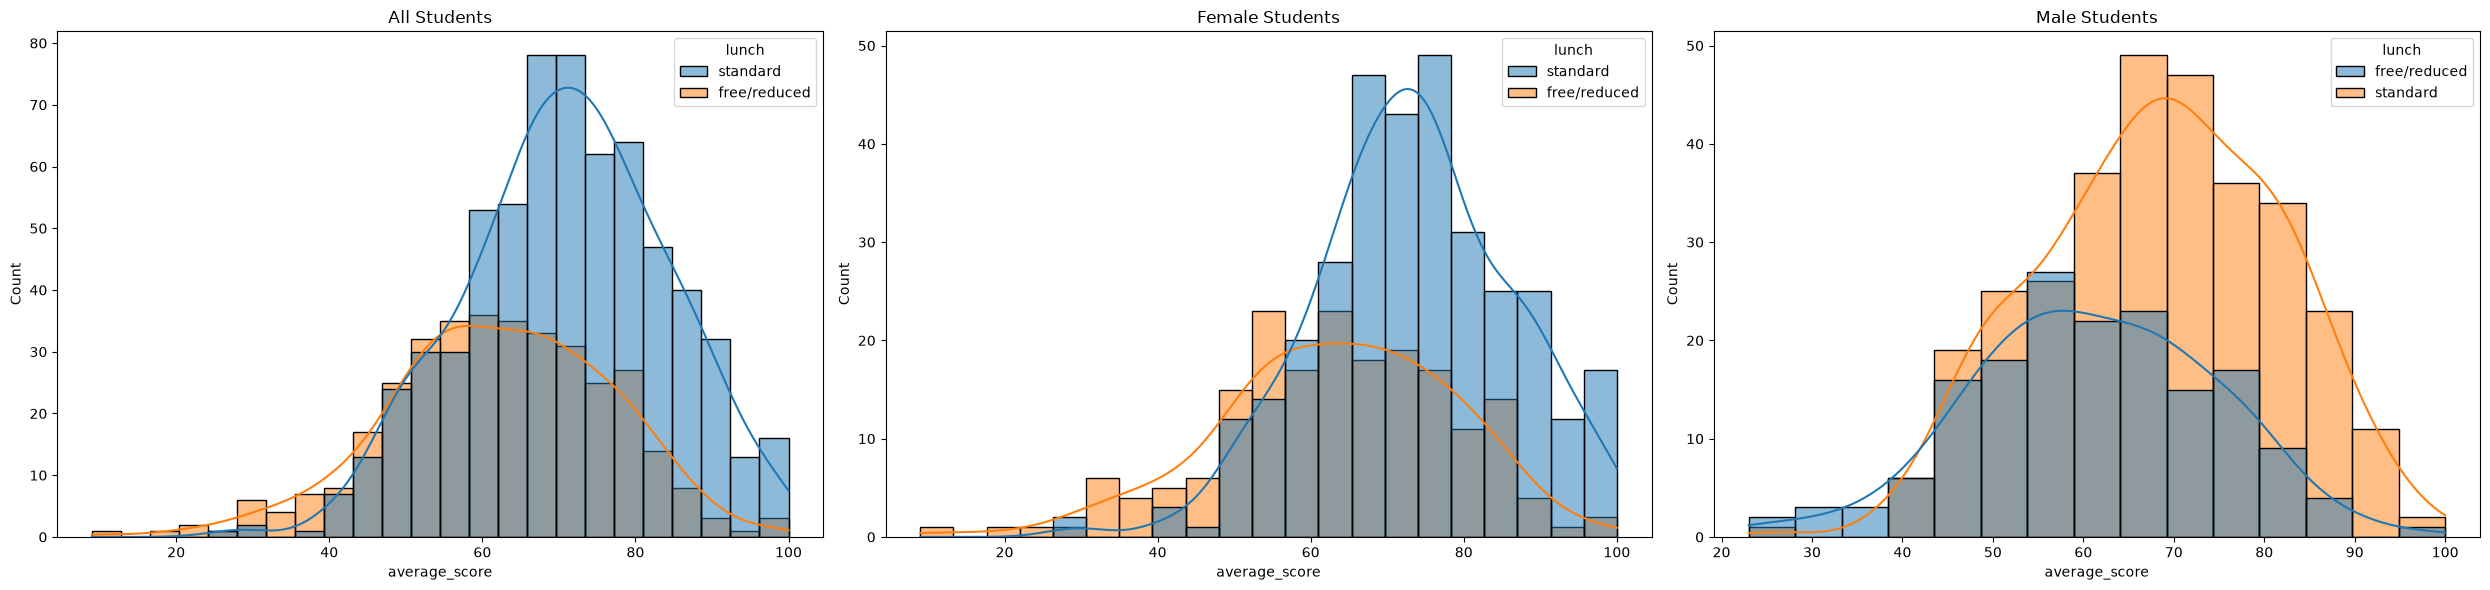

In [23]:
fig,axs = plt.subplots(1, 3, figsize=(25,6))

sns.histplot(data=df,x='average_score',kde=True,hue='lunch', ax = axs[0])

sns.histplot(data=df[df.gender=='female'],x='average_score',kde=True,hue='lunch', ax = axs[1]   )

sns.histplot(data=df[df.gender=='male'],x='average_score',kde=True,hue='lunch', ax = axs[2])

axs[0].set_title("All Students")
axs[1].set_title("Female Students")
axs[2].set_title("Male Students")

plt.tight_layout()
plt.show()


### Insights

* Students lunch helps perform well in exams
* Students lunch helps perform well in exams be it a male or female

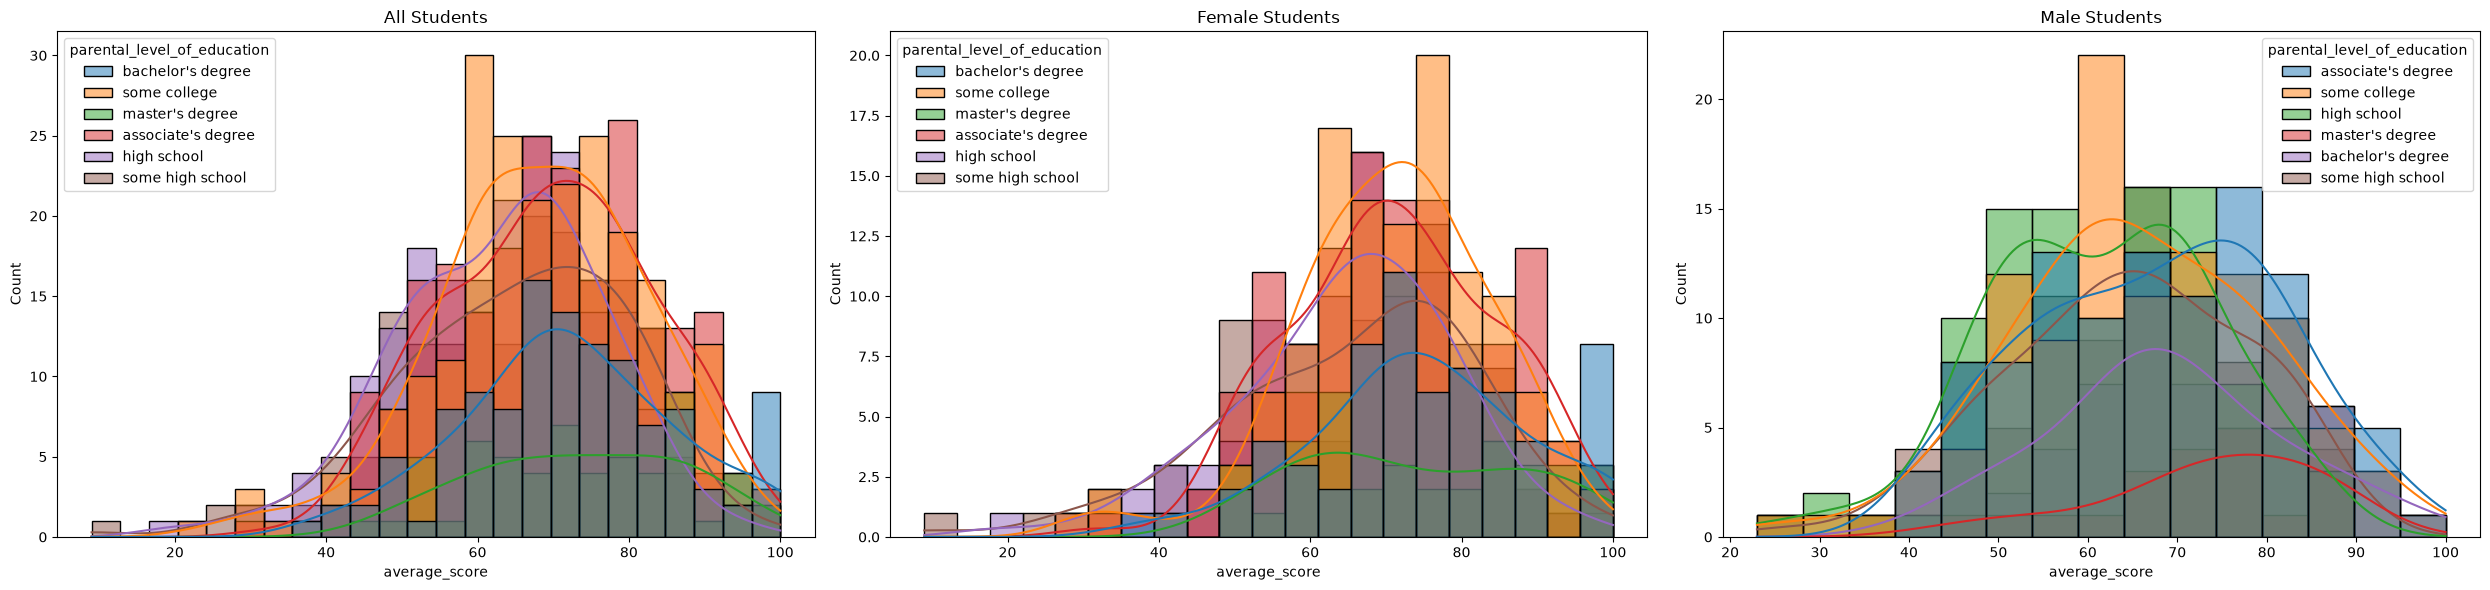

In [24]:
fig,axs = plt.subplots(1, 3, figsize=(25,6))

sns.histplot(data=df,x='average_score',kde=True,hue='parental_level_of_education', ax = axs[0])

sns.histplot(data=df[df.gender=='female'],x='average_score',kde=True,hue='parental_level_of_education', ax = axs[1]   )

sns.histplot(data=df[df.gender=='male'],x='average_score',kde=True,hue='parental_level_of_education', ax = axs[2])

axs[0].set_title("All Students")
axs[1].set_title("Female Students")
axs[2].set_title("Male Students")

plt.tight_layout()
plt.show()


### Insights

* In general parent's education don't help student perform well in exam
* 2nd plot we can see there is no effect of parents on female students.
* 3rd plot shows that parent's whose education is of assosciate degree or master's degree their male child tend to perform well in exam